# CS 463 Project — Modeling (one state per run)

Trains and saves every classical model for **one state**. The neural
networks are in `04_Neural_Networks.ipynb`.

Run it once per state; the state comes from the `STATE` environment
variable (default `CA`):

```
STATE=TX jupyter nbconvert --to notebook --execute 03_Modeling.ipynb --output 03_Modeling_TX.ipynb
```

**Models:** naive baselines → Linear / Ridge / LASSO → Random Forest (with
cross-validation) → XGBoost (squared error and Tweedie loss) → two-stage
hurdle model (custom model).

**Training rules (every model):**

- Training rows: dates before `TRAIN_END`, with suspected stockouts removed,
  so the models learn customer demand rather than shelf availability.
- Early stopping (XGBoost, hurdle model) uses the **last 10% of training
  dates**, never the validation set.
- Hyperparameters are chosen on the **validation** set by **RMSE** on
  non-stockout rows. RMSE is used because MAE rewards forecasts that run low
  on zero-heavy data.
- The **test** set is not used here. Model comparisons and results are
  reported in Update 4.

Every model is saved to `models/<state>/`, and its validation forecasts to
`results/<state>/validation_predictions.parquet`.

In [1]:
import json
import os
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, TimeSeriesSplit

from src import config
from src import data_prep as dp
from src import models as m
from src.evaluation import forecast_metrics

STATE = os.environ.get("STATE", "CA")
assert STATE in config.STATES, f"unknown state {STATE}"

MODEL_DIR = config.MODELS_DIR / STATE
RESULT_DIR = config.RESULTS_DIR / STATE
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Training-set sizes for the slower models (rows sampled at random)
LINEAR_SAMPLE = 2_000_000
FOREST_SAMPLE = 1_000_000
CV_FOLD_SAMPLE = 400_000

rng = np.random.default_rng(config.SEED)
print("State:", STATE, "| stores:", config.STATES[STATE])

State: WI | stores: ['WI_1', 'WI_2', 'WI_3']


## 1. Data

In [2]:
features = dp.load_features(STATE)
columns = ["store_id", "item_id", "cat_id", "date", "target_sales", "is_suspected_stockout"] + features

train = dp.load_split(STATE, "train", columns)
validation = dp.load_split(STATE, "validation", columns)

train_clean = train[train["is_suspected_stockout"] == 0].reset_index(drop=True)
del train

# Last 10% of training dates: early stopping only
stop_cutoff = train_clean["date"].quantile(0.9)
fit_rows = (train_clean["date"] < stop_cutoff).to_numpy()

X_train, y_train = train_clean[features], train_clean["target_sales"].to_numpy()
X_fit, y_fit = X_train[fit_rows], y_train[fit_rows]
X_stop, y_stop = X_train[~fit_rows], y_train[~fit_rows]

X_val, y_val = validation[features], validation["target_sales"].to_numpy()
val_clean = (validation["is_suspected_stockout"] == 0).to_numpy()

linear_rows = rng.choice(len(train_clean), min(LINEAR_SAMPLE, len(train_clean)), replace=False)
forest_rows = rng.choice(len(train_clean), min(FOREST_SAMPLE, len(train_clean)), replace=False)

pd.DataFrame({
    "rows": [len(train_clean), fit_rows.sum(), (~fit_rows).sum(), len(validation)],
    "dates": [
        f"{train_clean['date'].min().date()} to {train_clean['date'].max().date()}",
        f"to {train_clean.loc[fit_rows, 'date'].max().date()}",
        f"from {stop_cutoff.date()}",
        f"{validation['date'].min().date()} to {validation['date'].max().date()}",
    ],
}, index=["clean training rows", "  fit part", "  early-stopping part", "validation rows"]).style.format({"rows": "{:,}"})

,rows,dates
clean training rows,"6,338,619",2011-05-06 to 2014-10-07
fit part,"5,700,595",to 2014-07-08
early-stopping part,"638,024",from 2014-07-09
validation rows,"2,500,862",2014-10-08 to 2015-07-16


In [3]:
val_predictions = validation[["store_id", "item_id", "cat_id", "date", "target_sales", "is_suspected_stockout"]].copy()
tuning_log = []
model_summary = []


def val_rmse(pred):
    """Validation RMSE on non-stockout rows: the tuning criterion."""
    return forecast_metrics(y_val[val_clean], np.asarray(pred)[val_clean])["RMSE"]


def record(name, pred, hyperparameters, training_rows, seconds):
    """Stores a model's validation forecasts and its settings."""
    val_predictions[name] = np.maximum(0, np.asarray(pred)).astype(np.float32)
    model_summary.append({
        "model": name, "hyperparameters": hyperparameters,
        "training rows": training_rows, "train time (s)": round(seconds, 1),
    })

## 2. Naive baselines

Fixed rules with no training — the bar every model must beat:

- **Last week:** sales on the same weekday 7 days earlier (`sales_lag_7`)
- **28-day average:** average daily sales over the 28 days ending on order day

In [4]:
record("Baseline: last week", validation["sales_lag_7"], "none", 0, 0)
record("Baseline: 28-day average", validation["rolling_mean_28"], "none", 0, 0)

## 3. Linear models

Features are standardized first, so the penalties treat every feature
equally. Trained on a random sample of 2 million clean training rows: a
linear model has only one weight per feature, so more rows add little.

| Model | Loss |
|---|---|
| Linear Regression | Squared error |
| Ridge | Squared error + α‖w‖² (L2) |
| LASSO | Squared error + α‖w‖₁ (L1), which can set weights to exactly 0 |

In [5]:
X_lin, y_lin = X_train.iloc[linear_rows], y_train[linear_rows]

start = time.time()
linear = m.make_linear("linear").fit(X_lin, y_lin)
record("Linear Regression", linear.predict(X_val), "none", len(linear_rows), time.time() - start)
joblib.dump(linear, MODEL_DIR / "linear_regression.joblib")


def tune_linear(kind, alphas):
    """Fits one model per alpha and keeps the one with the lowest validation RMSE."""
    fitted = {}
    for alpha in alphas:
        start = time.time()
        model = m.make_linear(kind, alpha).fit(X_lin, y_lin)
        fitted[alpha] = (model, time.time() - start)
        tuning_log.append({"model": kind, "setting": f"alpha={alpha}", "validation RMSE": val_rmse(model.predict(X_val))})
    best = min(alphas, key=lambda a: next(r["validation RMSE"] for r in tuning_log if r["model"] == kind and r["setting"] == f"alpha={a}"))
    return best, *fitted[best]


ridge_alpha, ridge, ridge_seconds = tune_linear("ridge", [0.1, 10, 1000, 10000])
record(f"Ridge (alpha={ridge_alpha})", ridge.predict(X_val), f"alpha={ridge_alpha}", len(linear_rows), ridge_seconds)
joblib.dump(ridge, MODEL_DIR / "ridge.joblib")

lasso_alpha, lasso, lasso_seconds = tune_linear("lasso", [0.001, 0.01, 0.1])
record(f"LASSO (alpha={lasso_alpha})", lasso.predict(X_val), f"alpha={lasso_alpha}", len(linear_rows), lasso_seconds)
joblib.dump(lasso, MODEL_DIR / "lasso.joblib")

pd.DataFrame([r for r in tuning_log if r["model"] in ("ridge", "lasso")]).style.format({"validation RMSE": "{:.4f}"})

,model,setting,validation RMSE
0,ridge,alpha=0.1,2.2229
1,ridge,alpha=10,2.2229
2,ridge,alpha=1000,2.2230
3,ridge,alpha=10000,2.2237
4,lasso,alpha=0.001,2.2229
5,lasso,alpha=0.01,2.2244
6,lasso,alpha=0.1,2.2367


With the redundant one-hot columns removed, the linear weights are now
interpretable. Below are LASSO's largest weights (per standard deviation of
each feature) and the features it removed.

Features LASSO set to zero: ['month_10', 'month_11', 'event_type_Sporting', 'days_since_event']


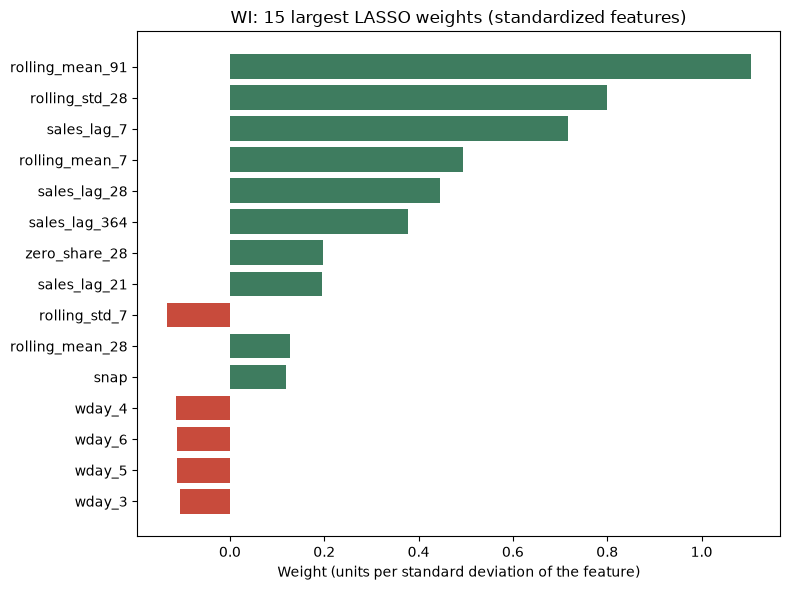

In [6]:
lasso_weights = pd.Series(lasso[-1].coef_, index=features)
print("Features LASSO set to zero:", list(lasso_weights[lasso_weights == 0].index) or "none")

top = lasso_weights.reindex(lasso_weights.abs().sort_values(ascending=False).index).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#3E7C5F", "#C84B3C"))
ax.set_title(f"{STATE}: 15 largest LASSO weights (standardized features)")
ax.set_xlabel("Weight (units per standard deviation of the feature)")
plt.tight_layout()
plt.show()

## 4. Random Forest

An ensemble of 100 CART regression trees, each grown on a bootstrap sample
of rows with 50% of features considered at each split; the forecast is the
average of the trees. Trained on a random sample of 1 million clean training
rows to keep training time reasonable.

| Hyperparameter | Value |
|---|---|
| Trees | 100 |
| Max depth | 14 |
| Min samples per leaf | 20 |
| Features per split | 50% |
| Split criterion (loss) | Squared error |

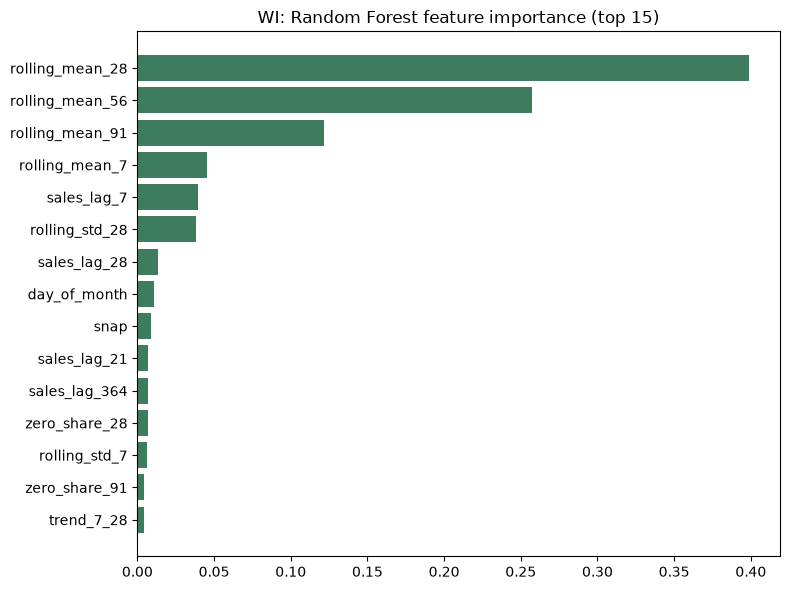

In [7]:
start = time.time()
forest = m.make_random_forest().fit(X_train.iloc[forest_rows], y_train[forest_rows])
record("Random Forest", forest.predict(X_val), "100 trees, depth 14, min leaf 20, 50% features", len(forest_rows), time.time() - start)
joblib.dump(forest, MODEL_DIR / "random_forest.joblib", compress=3)

importance = pd.Series(forest.feature_importances_, index=features).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importance.index, importance.values, color="#3E7C5F")
ax.set_title(f"{STATE}: Random Forest feature importance (top 15)")
plt.tight_layout()
plt.show()

### 4.1 Cross-validation for the Random Forest

Two kinds of 5-fold cross-validation on the **training** data, with the same
Random Forest settings and up to 400,000 training rows per fold:

1. **k-fold (`KFold`)** — rows shuffled into random folds. The textbook
   method, but it trains on days *after* the ones it scores, which a real
   forecast cannot do.
2. **Time-series (`TimeSeriesSplit`)** — folds split **by date**; each fold
   trains only on earlier dates and is scored on the period right after.

The spread across folds shows how stable the model is from period to period.

In [8]:
cv_data = train_clean.sort_values("date").reset_index(drop=True)
unique_dates = np.sort(cv_data["date"].unique())
row_dates = cv_data["date"].to_numpy()
cv_results = []


def cv_fold(method, fold, train_idx, score_idx):
    """Trains a Random Forest on one fold and scores it with WAPE (comparable across folds)."""
    if len(train_idx) > CV_FOLD_SAMPLE:
        train_idx = np.random.default_rng(config.SEED + fold).choice(train_idx, CV_FOLD_SAMPLE, replace=False)
    model = m.make_random_forest().fit(cv_data.iloc[train_idx][features], cv_data.iloc[train_idx]["target_sales"])
    score = cv_data.iloc[score_idx]
    metrics = forecast_metrics(score["target_sales"], model.predict(score[features]))
    cv_results.append({"method": method, "fold": fold, **metrics,
                       "scored from": score["date"].min().date(), "scored to": score["date"].max().date()})


kfold_rows = rng.choice(len(cv_data), 500_000, replace=False)
for fold, (tr, sc) in enumerate(KFold(5, shuffle=True, random_state=config.SEED).split(kfold_rows), start=1):
    cv_fold("KFold", fold, kfold_rows[tr], kfold_rows[sc])

for fold, (tr_d, sc_d) in enumerate(TimeSeriesSplit(5).split(unique_dates), start=1):
    cv_fold("TimeSeriesSplit", fold,
            np.flatnonzero(np.isin(row_dates, unique_dates[tr_d])),
            np.flatnonzero(np.isin(row_dates, unique_dates[sc_d])))

cv_table = pd.DataFrame(cv_results)
cv_table.to_csv(RESULT_DIR / "random_forest_cv.csv", index=False)
del cv_data

cv_table.groupby("method")[["WAPE", "RMSE", "Bias"]].agg(["mean", "std"]).style.format("{:.3f}")

**Reading this:** if k-fold's error is lower and barely varies between folds,
it is too optimistic and hides period-to-period changes — evidence that
random folds are misleading for time series.

## 5. XGBoost

Gradient-boosted trees: each new tree corrects the errors of the trees
before it. Two loss functions:

- **Squared error** — the standard regression loss.
- **Tweedie** — for non-negative targets with many exact zeros and a long
  right tail, like daily sales. The variance power `p` (1 = Poisson,
  2 = Gamma) is chosen on validation from {1.1, 1.3, 1.5, 1.7}, a range wide enough
  that the best value is not at its edge in every state.

| Hyperparameter | Value |
|---|---|
| Learning rate | 0.05 |
| Max depth | 8 |
| Min child weight | 10 |
| Row / column subsample | 0.8 / 0.8 |
| Trees | up to 3,000; early stopping after 50 rounds without improvement |

In [9]:
start = time.time()
xgb_mse = m.make_xgb_regressor("reg:squarederror").fit(X_fit, y_fit, eval_set=[(X_stop, y_stop)], verbose=False)
record("XGBoost (squared error)", xgb_mse.predict(X_val), f"{xgb_mse.best_iteration + 1} trees", len(X_fit), time.time() - start)
xgb_mse.save_model(MODEL_DIR / "xgb_squared_error.json")
print("Trees used:", xgb_mse.best_iteration + 1)

Trees used: 268


In [10]:
tweedie = {}
for power in [1.1, 1.3, 1.5, 1.7]:
    start = time.time()
    model = m.make_xgb_regressor("reg:tweedie", tweedie_variance_power=power).fit(
        X_fit, y_fit, eval_set=[(X_stop, y_stop)], verbose=False)
    pred = model.predict(X_val)
    tweedie[power] = (model, pred, time.time() - start)
    tuning_log.append({"model": "xgb_tweedie", "setting": f"p={power}", "validation RMSE": val_rmse(pred)})

best_power = min(tweedie, key=lambda p: val_rmse(tweedie[p][1]))
xgb_tweedie, pred, seconds = tweedie[best_power]
record(f"XGBoost (Tweedie, p={best_power})", pred, f"p={best_power}, {xgb_tweedie.best_iteration + 1} trees", len(X_fit), seconds)
xgb_tweedie.save_model(MODEL_DIR / "xgb_tweedie.json")
del tweedie

pd.DataFrame([r for r in tuning_log if r["model"] == "xgb_tweedie"]).style.format({"validation RMSE": "{:.4f}"})

,model,setting,validation RMSE
0,xgb_tweedie,p=1.1,2.0969
1,xgb_tweedie,p=1.3,2.0950
2,xgb_tweedie,p=1.5,2.1006
3,xgb_tweedie,p=1.7,2.1070


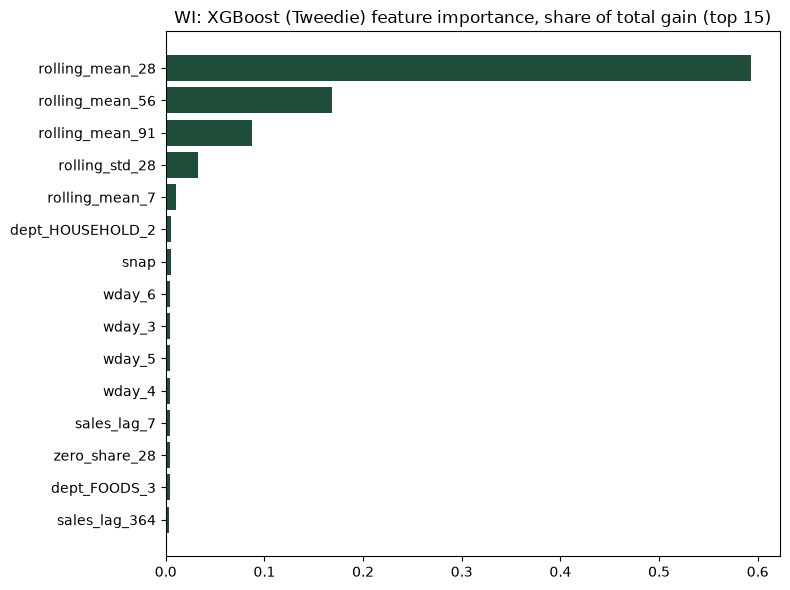

In [11]:
gain = pd.Series(xgb_tweedie.get_booster().get_score(importance_type="gain")).reindex(features).fillna(0)
gain = (gain / gain.sum()).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(gain.index, gain.values, color="#1F4D3A")
ax.set_title(f"{STATE}: XGBoost (Tweedie) feature importance, share of total gain (top 15)")
plt.tight_layout()
plt.show()

## 6. Two-stage hurdle model (custom model)

More than half of all product-days have zero sales. The hurdle model
(`src.models.HurdleRegressor`) splits the forecast into two questions:

1. **Stage 1 — classifier:** probability the product sells at least one unit
   (XGBoost, log loss, all clean training rows).
2. **Stage 2 — regressor:** units sold given a sale (XGBoost, Poisson loss on
   `sales − 1`, only days with sales), so this stage always forecasts ≥ 1.

**Forecast = P(sales > 0) × (1 + predicted extra units).** Both stages use the
XGBoost settings above with early stopping.

In [12]:
start = time.time()
hurdle = m.HurdleRegressor().fit(X_fit, y_fit, eval_set=(X_stop, y_stop))
record("Hurdle model (XGBoost + XGBoost)", hurdle.predict(X_val),
       f"stage 1: {hurdle.classifier_.best_iteration + 1} trees, stage 2: {hurdle.regressor_.best_iteration + 1} trees",
       len(X_fit), time.time() - start)
hurdle.save(MODEL_DIR / "hurdle")
print("Stage 1 trees:", hurdle.classifier_.best_iteration + 1, "| stage 2 trees:", hurdle.regressor_.best_iteration + 1)

Stage 1 trees: 713 | stage 2 trees: 843


## 7. Saved models and settings

Validation forecasts are saved for the Update 4 results; they are not
compared here.

In [13]:
val_predictions.to_parquet(RESULT_DIR / "validation_predictions.parquet", index=False)
pd.DataFrame(tuning_log).to_csv(RESULT_DIR / "tuning_log.csv", index=False)

summary = pd.DataFrame(model_summary)
summary.to_csv(RESULT_DIR / "model_summary.csv", index=False)

for path in sorted(MODEL_DIR.rglob("*")):
    if path.is_file():
        print(f"{str(path.relative_to(config.PROJECT_DIR)):45s} {path.stat().st_size / 1e6:7.1f} MB")

summary.style.format({"training rows": "{:,}"})

models/WI/hurdle/params.json                      0.0 MB
models/WI/hurdle/stage1_classifier.json          15.0 MB
models/WI/hurdle/stage2_regressor.json           24.0 MB
models/WI/lasso.joblib                            0.0 MB
models/WI/linear_regression.joblib                0.0 MB
models/WI/random_forest.joblib                   10.9 MB
models/WI/ridge.joblib                            0.0 MB
models/WI/xgb_squared_error.json                  4.2 MB
models/WI/xgb_tweedie.json                       11.9 MB


,model,hyperparameters,training rows,train time (s)
0,Baseline: last week,none,0,0.000000
1,Baseline: 28-day average,none,0,0.000000
2,Linear Regression,none,"2,000,000",2.400000
3,Ridge (alpha=0.1),alpha=0.1,"2,000,000",1.400000
4,LASSO (alpha=0.001),alpha=0.001,"2,000,000",12.700000
5,Random Forest,"100 trees, depth 14, min leaf 20, 50% features","1,000,000",61.400000
6,XGBoost (squared error),268 trees,"5,700,595",37.700000
7,"XGBoost (Tweedie, p=1.3)","p=1.3, 392 trees","5,700,595",71.500000
8,Hurdle model (XGBoost + XGBoost),"stage 1: 713 trees, stage 2: 843 trees","5,700,595",166.500000
